# Seoul Bike — итоговое сравнение ML-моделей

Сравниваем Dummy Baseline, Linear Regression, Random Forest и Gradient Boosting.

Все модели используют одинаковые признаки, временное разделение TRAIN/TEST и метрики MAE, RMSE, R².

Кросс-валидация и подбор гиперпараметров проводятся только на TRAIN. TEST используется для итоговой оценки.

In [8]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Загружаем общий датасет
data_path = Path("../data/processed/SeoulBikeData_clean.csv")
if not data_path.exists():
    data_path = Path("data/processed/SeoulBikeData_clean.csv")

df = pd.read_csv(data_path, parse_dates=["Date"])
df = df.sort_values(["Date", "Hour"]).reset_index(drop=True)

# Календарные признаки
df["month"] = df["Date"].dt.month
df["day_of_week"] = df["Date"].dt.day_of_week

# Признаки и целевая переменная
y = df["Rented Bike Count"]
X = df.drop(columns=["Rented Bike Count", "Date"])

# Разделение по времени: 80% / 20%
split = int(len(df) * 0.8)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()
y_train = y.iloc[:split].copy()
y_test = y.iloc[split:].copy()

assert len(df) == 8760
assert X_train.shape == (7008, 14)
assert X_test.shape == (1752, 14)
assert "Rented Bike Count" not in X.columns

categorical_features = ["Seasons", "Holiday", "Functioning Day"]
numeric_features = [c for c in X.columns if c not in categorical_features]

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])

print("Всего наблюдений:", len(df))
print("TRAIN:", X_train.shape, y_train.shape)
print("TEST:", X_test.shape, y_test.shape)
print("Последняя дата TRAIN:", df.iloc[split - 1]["Date"].date())
print("Первая дата TEST:", df.iloc[split]["Date"].date())
print("Подготовка завершена!")


Всего наблюдений: 8760
TRAIN: (7008, 14) (7008,)
TEST: (1752, 14) (1752,)
Последняя дата TRAIN: 2018-09-18
Первая дата TEST: 2018-09-19
Подготовка завершена!


## Обучение и сравнение моделей

Обучаем четыре модели на одинаковом TRAIN и оцениваем на общем TEST.

Для всех моделей отрицательные прогнозы ограничиваем нулём. Основная метрика — MAE, дополнительные — RMSE и R².

In [9]:

# Четыре модели для сравнения
models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": Pipeline([
        ("preprocessing", make_preprocessor()),
        ("model", LinearRegression())
    ]),

    "Random Forest": Pipeline([
        ("preprocessing", make_preprocessor()),
        ("model", RandomForestRegressor(
            n_estimators=400,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features=1.0,
            n_jobs=-1,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessing", make_preprocessor()),
        ("model", GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            random_state=42
        ))
    ])
}

# Обучаем и сравниваем
rows = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    raw_pred = model.predict(X_test)
    y_pred = np.clip(raw_pred, 0, None)

    predictions[name] = y_pred

    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    })

results = (
    pd.DataFrame(rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(results.round(3))

print("Лучшая по MAE:", results.iloc[0]["Model"])


,Model,MAE,RMSE,R2
0,Gradient Boosting,191.241,282.520,0.788
1,Random Forest,219.699,316.196,0.734
2,Linear Regression,294.743,400.536,0.574
3,Dummy Baseline,500.999,616.819,-0.011


Лучшая по MAE: Gradient Boosting


## Кросс-валидация по времени

Используем TimeSeriesSplit с 4 разделениями внутри TRAIN.

На каждом шаге модель обучается на прошлом и проверяется на более поздних данных. Между ними оставляем промежуток 24 часа.

Сравниваем среднее значение и разброс MAE, RMSE и R². TEST в кросс-валидации не участвует.

In [10]:

# Временная кросс-валидация: 4 проверки, промежуток 24 часа
tscv = TimeSeriesSplit(n_splits=4, gap=24)

# Для сравнения используем тот же clip, что и в итоговой таблице.
# sklearn максимизирует score, поэтому ошибки возвращаем со знаком минус.
def cv_mae(model, X_valid, y_valid):
    pred = np.clip(model.predict(X_valid), 0, None)
    return -mean_absolute_error(y_valid, pred)

def cv_rmse(model, X_valid, y_valid):
    pred = np.clip(model.predict(X_valid), 0, None)
    return -root_mean_squared_error(y_valid, pred)

def cv_r2(model, X_valid, y_valid):
    pred = np.clip(model.predict(X_valid), 0, None)
    return r2_score(y_valid, pred)

scoring = {
    "MAE": cv_mae,
    "RMSE": cv_rmse,
    "R2": cv_r2
}

# Проверяем все четыре модели только на TRAIN
cv_rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    mae_scores = -scores["test_MAE"]
    rmse_scores = -scores["test_RMSE"]
    r2_scores = scores["test_R2"]

    cv_rows.append({
        "Model": name,
        "MAE_mean": mae_scores.mean(),
        "MAE_std": mae_scores.std(),
        "RMSE_mean": rmse_scores.mean(),
        "RMSE_std": rmse_scores.std(),
        "R2_mean": r2_scores.mean(),
        "R2_std": r2_scores.std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("MAE_mean")
display(cv_results.round(3))


,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
3,Gradient Boosting,239.387,83.858,336.567,91.600,0.630,0.127
2,Random Forest,256.190,85.089,364.972,95.707,0.569,0.136
1,Linear Regression,404.434,149.106,524.343,164.156,0.197,0.135
0,Dummy Baseline,537.221,212.184,720.082,262.170,-0.471,0.297


## Подбор гиперпараметров — GridSearchCV

Подбираем количество деревьев и их глубину для Gradient Boosting.

Используем 4 комбинации параметров и TimeSeriesSplit на TRAIN. Критерий выбора — минимальный MAE после clip. TEST не участвует в подборе.

In [11]:

# Создаём модель для подбора параметров
tuning_pipeline = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", GradientBoostingRegressor(
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    ))
])

# Всего 2 × 2 = 4 комбинации
param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [3, 4]
}

grid = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring=cv_mae,
    cv=tscv,
    n_jobs=1,
    refit=True,
    error_score="raise"
)

grid.fit(X_train, y_train)

# Результаты всех комбинаций
tuning_results = pd.DataFrame(grid.cv_results_)[[
    "param_model__n_estimators",
    "param_model__max_depth",
    "mean_test_score",
    "std_test_score"
]].copy()

tuning_results["MAE_mean"] = -tuning_results["mean_test_score"]

display(
    tuning_results[[
        "param_model__n_estimators",
        "param_model__max_depth",
        "MAE_mean",
        "std_test_score"
    ]].sort_values("MAE_mean").round(3)
)

print("Лучшие параметры:", grid.best_params_)
print("Лучший MAE на CV:", round(-grid.best_score_, 3))
print("Исходный MAE на CV:", round(
    cv_results.loc[
        cv_results["Model"] == "Gradient Boosting",
        "MAE_mean"
    ].iloc[0], 3
))

best_gb_model = grid.best_estimator_


,param_model__n_estimators,param_model__max_depth,MAE_mean,std_test_score
3,300,4,239.387,83.858
2,200,4,242.122,81.946
1,300,3,247.961,79.721
0,200,3,259.276,81.448


Лучшие параметры: {'model__max_depth': 4, 'model__n_estimators': 300}
Лучший MAE на CV: 239.387
Исходный MAE на CV: 239.387


## Проверка нового признака is_weekend

Сравниваем Gradient Boosting с исходными 14 признаками и с дополнительным признаком выходного дня.

Используем одинаковую временную кросс-валидацию только на TRAIN. Проверяем, помогает ли новый признак уменьшить MAE.

In [12]:

# Добавляем признак выходного дня только в копию TRAIN
X_train_weekend = X_train.copy()
X_train_weekend["is_weekend"] = (
    X_train_weekend["day_of_week"] >= 5
).astype(int)

# Preprocessing с дополнительным числовым признаком
weekend_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features + ["is_weekend"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

# Те же параметры Gradient Boosting
weekend_model = Pipeline([
    ("preprocessing", weekend_preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        random_state=42
    ))
])

# Проверка только на TRAIN
weekend_scores = cross_validate(
    weekend_model,
    X_train_weekend,
    y_train,
    cv=tscv,
    scoring={"MAE": cv_mae},
    n_jobs=1,
    error_score="raise"
)

original_mae = -grid.best_score_
weekend_mae = -weekend_scores["test_MAE"].mean()

feature_results = pd.DataFrame([
    {"Features": "Original (14)", "CV_MAE": original_mae},
    {"Features": "With is_weekend (15)", "CV_MAE": weekend_mae}
])

display(feature_results.round(3))

print("Разница MAE:", round(original_mae - weekend_mae, 3))
print("Новый признак улучшил результат:", weekend_mae < original_mae)


,Features,CV_MAE
0,Original (14),239.387
1,With is_weekend (15),237.371


Разница MAE: 2.016
Новый признак улучшил результат: True


## Итоговые результаты

На TRAIN выполнены кросс-валидация, подбор гиперпараметров и проверка дополнительного признака is_weekend.

Лучшие параметры Gradient Boosting: 300 деревьев, глубина 4.

Добавление is_weekend уменьшило средний MAE на кросс-валидации с 239.387 до 237.371.

Ниже проверяем выбранный вариант на TEST и сравниваем результаты моделей.

,Model,MAE,RMSE,R2
0,Gradient Boosting + is_weekend,184.001,275.970,0.798
1,Gradient Boosting,191.241,282.520,0.788
2,Random Forest,219.699,316.196,0.734
3,Linear Regression,294.743,400.536,0.574
4,Dummy Baseline,500.999,616.819,-0.011


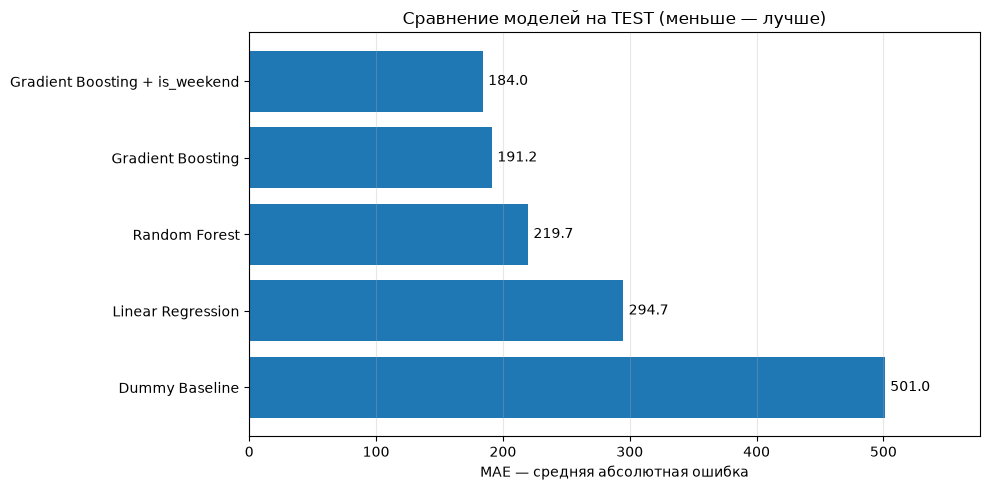

Лучшая модель на TEST: Gradient Boosting + is_weekend


In [13]:

# Добавляем is_weekend в тестовые признаки
X_test_weekend = X_test.copy()
X_test_weekend["is_weekend"] = (
    X_test_weekend["day_of_week"] >= 5
).astype(int)

# Обучаем выбранную модель на всём TRAIN
weekend_model.fit(X_train_weekend, y_train)

# Получаем прогноз на TEST
weekend_pred = np.clip(
    weekend_model.predict(X_test_weekend),
    0,
    None
)

# Добавляем результат в общую таблицу
weekend_result = pd.DataFrame([{
    "Model": "Gradient Boosting + is_weekend",
    "MAE": mean_absolute_error(y_test, weekend_pred),
    "RMSE": root_mean_squared_error(y_test, weekend_pred),
    "R2": r2_score(y_test, weekend_pred)
}])

final_results = (
    pd.concat([results, weekend_result], ignore_index=True)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(final_results.round(3))

# График сравнения моделей по MAE на TEST
plt.figure(figsize=(10, 5))

bars = plt.barh(
    final_results["Model"],
    final_results["MAE"]
)

plt.bar_label(bars, fmt="%.1f", padding=4)
plt.gca().invert_yaxis()

plt.xlabel("MAE — средняя абсолютная ошибка")
plt.title("Сравнение моделей на TEST (меньше — лучше)")
plt.xlim(0, final_results["MAE"].max() * 1.15)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Лучшая модель на TEST:", final_results.iloc[0]["Model"])
